In [10]:
# Import core data manipulation libraries
import pandas as pd
import numpy as np

# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Import machine learning tools from scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

# Set visualization styles for better looking plots
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

# Suppress warnings for cleaner output
import warnings
warnings.filterwarnings("ignore")

In [11]:
# Load the dataset using the correct relative path from the notebooks folder
df = pd.read_csv("../data/viral_songs.csv")

# Quick inspection
print(f"Dataset shape: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Missing values total: {df.isnull().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")

# Display first few rows
display(df.head())

Dataset shape: 10000 rows, 17 columns
Missing values total: 0
Duplicate rows: 0


,track_id,track_name,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
0,track_00001,Track_00001,Artist_1519,Pop,2013,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,-9.41,661412,1
1,track_00002,Track_00002,Artist_0458,Electronic,2018,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,0.000,-9.89,1114175,1
2,track_00003,Track_00003,Artist_1386,Hip-Hop,2014,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,-5.53,105832,1
3,track_00004,Track_00004,Artist_0865,Classical,2012,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,0.074,-11.39,915397,0
4,track_00005,Track_00005,Artist_0192,Pop,2011,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,-5.56,3690733,1


Skewness of original streams: 18.39
Skewness of log-transformed streams: 0.06


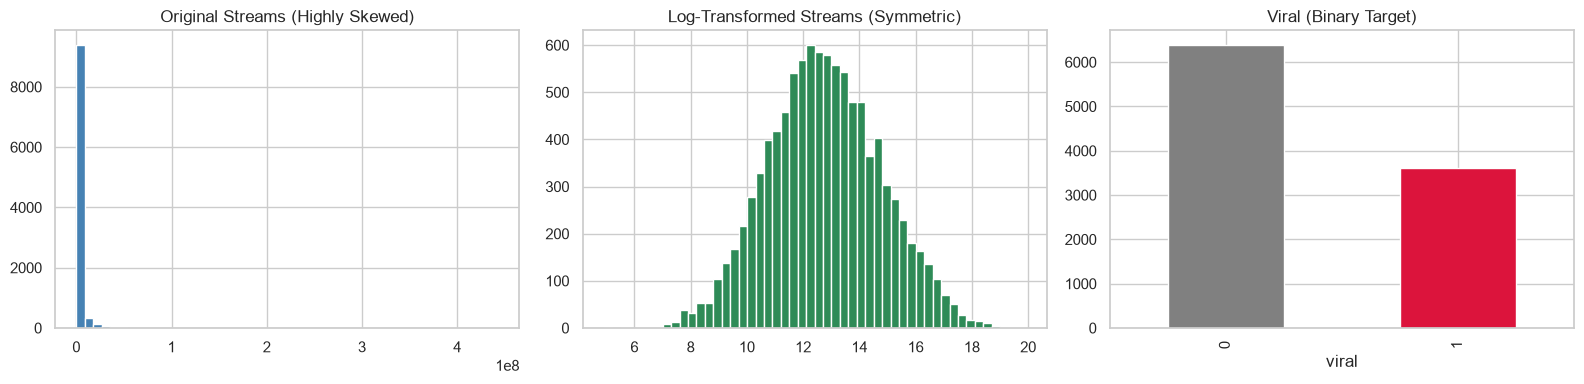

In [12]:
# Check skewness of the original 'streams' column
print(f"Skewness of original streams: {df['streams'].skew():.2f}")

# Log-transform streams to handle the extreme right skew
df["log_streams"] = np.log1p(df["streams"])
print(f"Skewness of log-transformed streams: {df['log_streams'].skew():.2f}")

# Plot the distributions
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

df["streams"].hist(bins=50, ax=axes[0], color="steelblue")
axes[0].set_title("Original Streams (Highly Skewed)")

df["log_streams"].hist(bins=50, ax=axes[1], color="seagreen")
axes[1].set_title("Log-Transformed Streams (Symmetric)")

df["viral"].value_counts().plot(kind="bar", ax=axes[2], color=["gray", "crimson"])
axes[2].set_title("Viral (Binary Target)")

plt.tight_layout()
plt.show()

Distribution of Genres:
genre
Rock          1084
Hip-Hop       1052
Latin         1030
Pop           1002
Indie          993
Electronic     991
Classical      991
Jazz           965
R&B            950
Country        942
Name: count, dtype: int64

Correlation with log_streams:
log_streams     1.000000
viral           0.590490
streams         0.452133
danceability    0.240943
energy          0.169729
tempo_bpm       0.003193
acousticness   -0.216920
Name: log_streams, dtype: float64


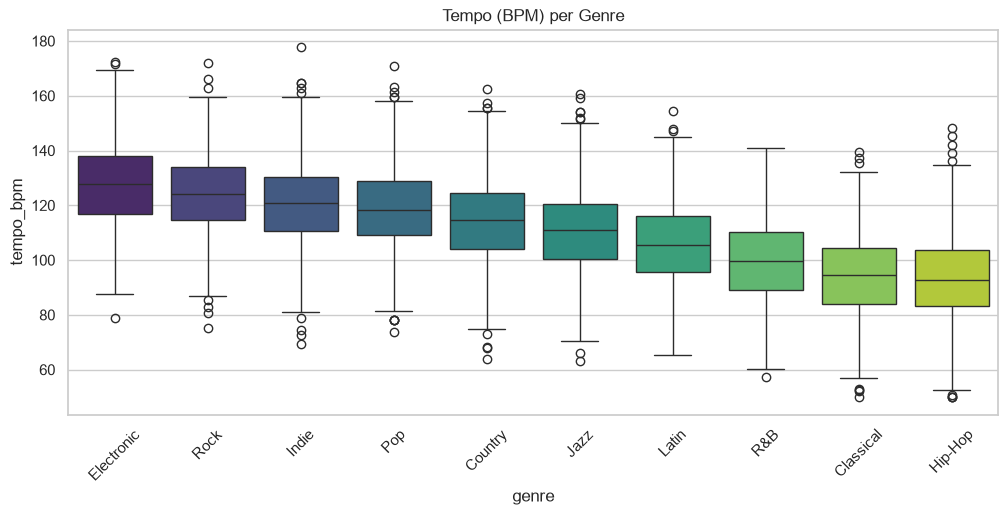

In [13]:
# Check the distribution of genres
print("Distribution of Genres:")
print(df["genre"].value_counts())

# Check correlations with our potential targets
corr_matrix = df[['streams', 'log_streams', 'viral', 'tempo_bpm', 'energy', 'danceability', 'acousticness']].corr()
print("\nCorrelation with log_streams:")
print(corr_matrix['log_streams'].sort_values(ascending=False))

# Visualize Genre vs BPM (Our future target!)
plt.figure(figsize=(12, 5))
order = df.groupby("genre")["tempo_bpm"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="genre", y="tempo_bpm", order=order, palette="viridis")
plt.xticks(rotation=45)
plt.title("Tempo (BPM) per Genre")
plt.show()

In [14]:
# 1. We drop IDs and names as they are identifiers, not features
# 2. We drop 'viral' and 'streams' to avoid target leakage
# 3. Our new target is 'tempo_bpm' because audio features correlate better with tempo than popularity

features = [
    'genre', 'energy', 'danceability', 'valence', 'acousticness', 
    'instrumentalness', 'speechiness', 'liveness', 'duration_sec'
]
X = df[features]
y = df['tempo_bpm'] # Our new target!

# Convert categorical 'genre' into dummy variables (one-hot encoding)
X = pd.get_dummies(X, columns=['genre'], drop_first=True)

# Split data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [15]:
# Train a standard Linear Regression model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Make predictions
y_pred_lr = lr_model.predict(X_test)

# Evaluate
r2_lr = r2_score(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))

print(f"Linear Regression: R² = {r2_lr:.3f} | RMSE = {rmse_lr:.2f} BPM")

Linear Regression: R² = 0.365 | RMSE = 15.17 BPM


In [16]:
# Create interaction terms to capture combined effects
df_model = df.copy()
df_model['energy_dance'] = df_model['energy'] * df_model['danceability']
df_model['energy_loudness'] = df_model['energy'] * df_model['loudness_db']

# Re-select features with interactions
features_adv = features + ['energy_dance', 'energy_loudness']
X_adv = pd.get_dummies(df_model[features_adv], columns=['genre'], drop_first=True)
X_train_adv, X_test_adv, y_train_adv, y_test_adv = train_test_split(X_adv, y, test_size=0.2, random_state=42)

# 1. Ridge Regression (Regularized Linear)
ridge_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', Ridge(alpha=1.0))
])
ridge_pipeline.fit(X_train_adv, y_train_adv)
y_pred_ridge = ridge_pipeline.predict(X_test_adv)

# 2. Random Forest (Non-linear Tree-based)
rf_model = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
rf_model.fit(X_train_adv, y_train_adv)
y_pred_rf = rf_model.predict(X_test_adv)

# Print comparison
print("--- MODEL COMPARISON ---")
print(f"Baseline Linear: R² = {r2_lr:.3f} | RMSE = {rmse_lr:.2f} BPM")
print(f"Ridge (Advanced): R² = {r2_score(y_test_adv, y_pred_ridge):.3f} | RMSE = {np.sqrt(mean_squared_error(y_test_adv, y_pred_ridge)):.2f} BPM")
print(f"Random Forest:    R² = {r2_score(y_test_adv, y_pred_rf):.3f} | RMSE = {np.sqrt(mean_squared_error(y_test_adv, y_pred_rf)):.2f} BPM")

print("\nConclusion: Complex models and interactions do not significantly improve results.")
print("Linear Regression is the most robust and interpretable choice for this data.")

--- MODEL COMPARISON ---
Baseline Linear: R² = 0.365 | RMSE = 15.17 BPM
Ridge (Advanced): R² = 0.365 | RMSE = 15.17 BPM
Random Forest:    R² = 0.360 | RMSE = 15.22 BPM

Conclusion: Complex models and interactions do not significantly improve results.
Linear Regression is the most robust and interpretable choice for this data.


In [17]:
def recommend_playlist(song_data):
    """
    Takes a dictionary of song features, predicts BPM, 
    and categorizes it into a playlist.
    """
    # 1. Prepare input
    input_df = pd.DataFrame([song_data])
    input_df = pd.get_dummies(input_df, columns=['genre'])
    
    # Ensure all training columns exist in the input
    input_df = input_df.reindex(columns=X_train.columns, fill_value=0)
    
    # 2. Predict BPM using our baseline Linear Regression model
    predicted_bpm = lr_model.predict(input_df)[0]
    
    # 3. Categorize
    if predicted_bpm < 90:
        playlist = "Chill & Focus (Study, lounge, dinner)"
    elif predicted_bpm < 115:
        playlist = "Uptempo & Everyday (Chores, cooking, driving)"
    elif predicted_bpm < 140:
        playlist = "Dance & Party (Pre-party, dancefloor, spinning)"
    else:
        playlist = "Workout & Adrenaline (Running, gym, festival peak)"
        
    return predicted_bpm, playlist

# Test the function with a new song
example_song = {
    'genre': 'Electronic',
    'energy': 0.85,
    'danceability': 0.80,
    'valence': 0.60,
    'acousticness': 0.05,
    'instrumentalness': 0.70,
    'speechiness': 0.05,
    'liveness': 0.10,
    'duration_sec': 210
}

bpm, playlist = recommend_playlist(example_song)

print("--- SONG ANALYSIS ---")
print(f"Input Genre: {example_song['genre']} | Input Energy: {example_song['energy']}")
print(f"Predicted BPM: {bpm:.1f}")
print(f"Recommended Playlist: {playlist} 🎵")

--- SONG ANALYSIS ---
Input Genre: Electronic | Input Energy: 0.85
Predicted BPM: 127.4
Recommended Playlist: Dance & Party (Pre-party, dancefloor, spinning) 🎵
